In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from datetime import datetime
from collections import Counter
from Bio import SeqIO
from Bio.Align import substitution_matrices

# Load BLOSUM62 Matrix
blosum62 = substitution_matrices.load("BLOSUM62")

def load_fasta(fasta_path):
    print(f"Loading FASTA: {fasta_path}...")
    all_parsed_data = []
    for record in SeqIO.parse(fasta_path, "fasta"):
        fields = record.id.split('|')
        if len(fields) < 6:
            continue
        unique_id = fields[0].strip()
        subtype   = fields[1].strip()
        clade     = fields[2].strip()
        date_str  = fields[3].strip()
        country   = fields[4].strip()
        zone      = fields[5].strip()
        try:
            date = datetime.strptime(date_str, '%Y-%m-%d')
            # Keep gaps (-), only remove stop codons (*)
            raw_seq = str(record.seq).replace('*', '')
            
            # Check length and cut conditionally
            if len(raw_seq) >= 553:
                sequence = raw_seq[16:]
            else:
                sequence = raw_seq
                
            all_parsed_data.append(dict(
                date=date, sequence=sequence,
                id_full_header=record.id, unique_id=unique_id,
                clade=clade, subtype=subtype, country=country, zone=zone
            ))
        except ValueError:
            continue
            
    df = pd.DataFrame(all_parsed_data)
    print(f"Total records: {len(df)}")
    return df

# --- EXECUTE ---
# Replace 'your_sequences.fasta' with your actual file path
df_fasta = load_fasta('h3n2_clean.fasta')

Loading FASTA: h3n2_clean.fasta...
Total records: 193102


In [41]:
def get_season(date_val):
    """
    Season is defined as July 1st of year Y to Jan 31st of year Y+1.
    Returns the year Y, or None if outside these months.
    """
    year = date_val.year
    month = date_val.month
    
    if month >= 7:
        return year
    elif month == 1:
        return year - 1
    return None # Ignores Feb-June

# Apply season mapping
df_fasta['Season'] = df_fasta['date'].apply(get_season)
df_fasta = df_fasta.dropna(subset=['Season'])
df_fasta['Season'] = df_fasta['Season'].astype(int)

def get_consensus(sequences):
    """Calculates the consensus sequence from a list of sequences."""
    if not sequences:
        return ""
    
    seq_length = len(sequences[0])
    consensus = []
    
    for i in range(seq_length):
        column = [seq[i] for seq in sequences if i < len(seq)]
        if not column:
            break
        most_common = Counter(column).most_common(1)[0][0]
        consensus.append(most_common)
        
    return "".join(consensus)

def calc_blosum_distance(seq1, seq2):
    """
    Calculates distance using BLOSUM62. 
    Distance = max(BLOSUM(a,a), BLOSUM(b,b)) - BLOSUM(a,b)
    Penalty for gaps/unknowns is arbitrarily set to 4.
    """
    dist = 0
    for a, b in zip(seq1, seq2):
        if a == b:
            continue
        try:
            # Look up score (matrix is symmetric, but Biopython uses tuples)
            score = blosum62.get((a, b), blosum62.get((b, a), -4)) 
            max_score = max(blosum62.get((a, a), 4), blosum62.get((b, b), 4))
            dist += (max_score - score)
        except Exception:
            dist += 4 # Generic penalty for unexpected characters
    return dist

In [42]:
from itertools import chain

epitope_sites = {
    'A': [122, 124, 126, 130, 131, 132, 133, 135, 137, 138, 140, 142, 143, 144, 145, 146, 150, 152, 168],
    'B': [128, 129, 155, 156, 157, 158, 159, 160, 163, 164, 165, 186, 187, 188, 189, 190, 192, 193, 194, 196, 197, 198],
    'C': [44, 45, 46, 47, 48, 50, 51, 53, 54, 273, 275, 276, 278, 279, 280, 294, 297, 299, 300, 304, 305, 307, 308, 309, 310, 311, 312],
    'D': [96, 102, 103, 117, 121, 167, 170, 171, 172, 173, 174, 175, 176, 177, 179, 182, 201, 203, 207, 208, 209, 212, 213, 214, 215, 216, 217, 218, 219, 226, 227, 228, 229, 230, 238, 240, 242, 244, 246, 247, 248],
    'E': [57, 59, 62, 63, 67, 75, 78, 80, 81, 82, 83, 86, 87, 88, 91, 92, 94, 109, 260, 261, 262, 265]
}

ALL_EPITOPE_POSITIONS_1BASED = sorted(set(chain.from_iterable(epitope_sites.values())))
EPITOPE_INDICES_0BASED = [p - 1 for p in ALL_EPITOPE_POSITIONS_1BASED]

print(f"Total epitope positions: {len(EPITOPE_INDICES_0BASED)}")

import pandas as pd

# List to hold the output data
distance_records = []
target_seasons = range(2014, 2026) # 2014 to 2025

print("Calculating Distances (All Positions vs Epitopes)...")

for target_year in target_seasons:
    prev_year = target_year - 1
    
    # 1. Get previous season sequences and calculate global consensus
    df_prev = df_fasta[df_fasta['Season'] == prev_year]
    if df_prev.empty:
        print(f"  [!] No data for previous season {prev_year}. Skipping target {target_year}.")
        continue
        
    prev_consensus = get_consensus(df_prev['sequence'].tolist())
    
    # 2. Get target season data
    df_target = df_fasta[df_fasta['Season'] == target_year]
    if df_target.empty:
        continue
        
    # 3. Get unique sequences per zone for the target season
    # (Assuming you want to track by 'zone'. Adjust if your column is named differently)
    df_unique_target = df_target.drop_duplicates(subset=['zone', 'sequence'])
    
    # 4. Calculate distances
    for _, row in df_unique_target.iterrows():
        seq = row['sequence']
        
        # A. Distance for ALL positions
        dist_all = calc_blosum_distance(prev_consensus, seq)
        
        # B. Distance for EPITOPE positions only
        # Safely extract just the epitope characters (checking length bounds)
        prev_cons_epi = "".join([prev_consensus[i] for i in EPITOPE_INDICES_0BASED if i < len(prev_consensus)])
        seq_epi = "".join([seq[i] for i in EPITOPE_INDICES_0BASED if i < len(seq)])
        
        dist_epitope = calc_blosum_distance(prev_cons_epi, seq_epi)
        
        distance_records.append({
            'Season': target_year,
            'Zone': row['zone'],
            'Distance_All': dist_all,
            'Distance_Epitope': dist_epitope
        })

# Create the final DataFrame
df_distances = pd.DataFrame(distance_records)
print(f"Calculated distances for {len(df_distances)} unique sequence-zone pairs.")

Total epitope positions: 131
Calculating Distances (All Positions vs Epitopes)...
Calculated distances for 33189 unique sequence-zone pairs.


In [43]:
from itertools import chain
def calc_hamming_distance(seq1, seq2):
    """Calculates the Hamming distance between two sequences of equal length."""
    # Optional: ensure sequences are the same length
    if len(seq1) != len(seq2):
        raise ValueError("Sequences must be of equal length to calculate Hamming distance.")
        
    # Count the number of positions where characters differ
    return sum(c1 != c2 for c1, c2 in zip(seq1, seq2))

epitope_sites = {
    'A': [122, 124, 126, 130, 131, 132, 133, 135, 137, 138, 140, 142, 143, 144, 145, 146, 150, 152, 168],
    'B': [128, 129, 155, 156, 157, 158, 159, 160, 163, 164, 165, 186, 187, 188, 189, 190, 192, 193, 194, 196, 197, 198],
    'C': [44, 45, 46, 47, 48, 50, 51, 53, 54, 273, 275, 276, 278, 279, 280, 294, 297, 299, 300, 304, 305, 307, 308, 309, 310, 311, 312],
    'D': [96, 102, 103, 117, 121, 167, 170, 171, 172, 173, 174, 175, 176, 177, 179, 182, 201, 203, 207, 208, 209, 212, 213, 214, 215, 216, 217, 218, 219, 226, 227, 228, 229, 230, 238, 240, 242, 244, 246, 247, 248],
    'E': [57, 59, 62, 63, 67, 75, 78, 80, 81, 82, 83, 86, 87, 88, 91, 92, 94, 109, 260, 261, 262, 265]
}

ALL_EPITOPE_POSITIONS_1BASED = sorted(set(chain.from_iterable(epitope_sites.values())))
EPITOPE_INDICES_0BASED = [p - 1 for p in ALL_EPITOPE_POSITIONS_1BASED]

print(f"Total epitope positions: {len(EPITOPE_INDICES_0BASED)}")

import pandas as pd

# List to hold the output data
distance_records = []
target_seasons = range(2014, 2026) # 2014 to 2025

print("Calculating Distances (All Positions vs Epitopes)...")

for target_year in target_seasons:
    prev_year = target_year - 1
    
    # 1. Get previous season sequences and calculate global consensus
    df_prev = df_fasta[df_fasta['Season'] == prev_year]
    if df_prev.empty:
        print(f"  [!] No data for previous season {prev_year}. Skipping target {target_year}.")
        continue
        
    prev_consensus = get_consensus(df_prev['sequence'].tolist())
    
    # 2. Get target season data
    df_target = df_fasta[df_fasta['Season'] == target_year]
    if df_target.empty:
        continue
        
    # 3. Get unique sequences per zone for the target season
    # (Assuming you want to track by 'zone'. Adjust if your column is named differently)
    df_unique_target = df_target.drop_duplicates(subset=['zone', 'sequence'])
    
    # 4. Calculate distances
    for _, row in df_unique_target.iterrows():
        seq = row['sequence']
        
        # A. Distance for ALL positions
        dist_all = calc_hamming_distance(prev_consensus, seq)
        
        # B. Distance for EPITOPE positions only
        # Safely extract just the epitope characters (checking length bounds)
        prev_cons_epi = "".join([prev_consensus[i] for i in EPITOPE_INDICES_0BASED if i < len(prev_consensus)])
        seq_epi = "".join([seq[i] for i in EPITOPE_INDICES_0BASED if i < len(seq)])
        
        dist_epitope = calc_hamming_distance(prev_cons_epi, seq_epi)
        
        distance_records.append({
            'Season': target_year,
            'Zone': row['zone'],
            'Distance_All': dist_all,
            'Distance_Epitope': dist_epitope
        })
# Create the final DataFrame
df_distances = pd.DataFrame(distance_records)
print(f"Calculated distances for {len(df_distances)} unique sequence-zone pairs.")

Total epitope positions: 131
Calculating Distances (All Positions vs Epitopes)...
Calculated distances for 33189 unique sequence-zone pairs.


Generating Independent Density plots for Evolutionary Drift...


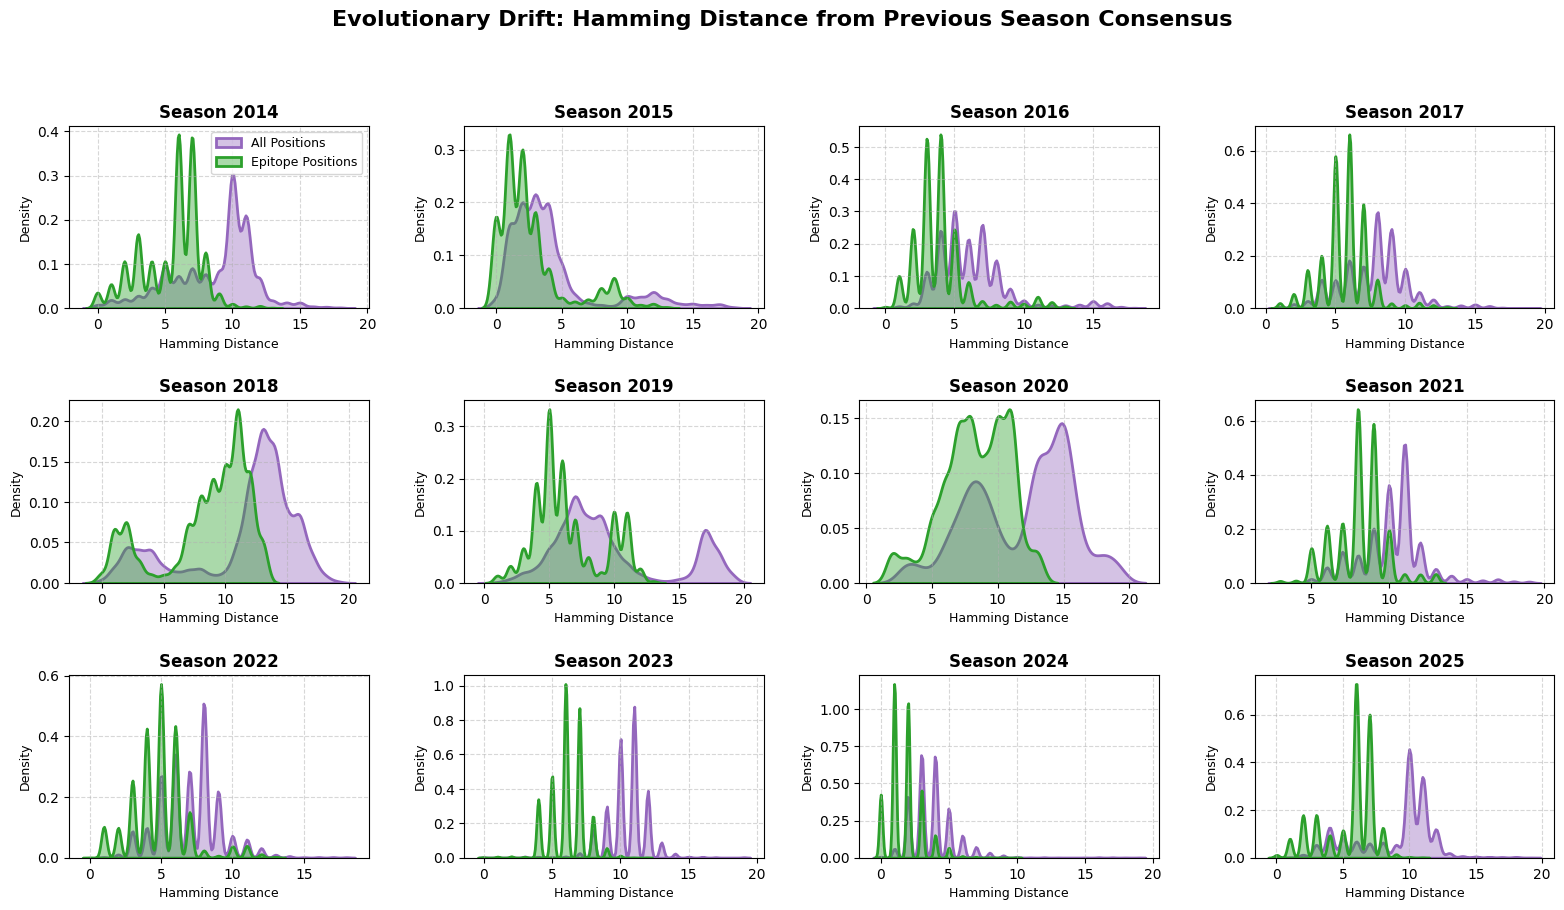

In [44]:
def plot_evolutionary_drift_density_unshared(df, col_all='Distance_All', col_epitope='Distance_Epitope'):
    print("Generating Independent Density plots for Evolutionary Drift...")
        
    if df.empty:
        print("No data available to plot.")
        return
        
    # Cap extreme outliers for cleaner visuals (top 1% of both columns)
    x_max_all = df[col_all].quantile(0.99) 
    x_max_epi = df[col_epitope].quantile(0.99)
    df_plot = df[(df[col_all] <= x_max_all) & (df[col_epitope] <= x_max_epi)].copy()

    # Add minor jitter to prevent flat lines on low-variance distributions
    df_plot[col_all] += np.random.normal(0, 0.05, size=len(df_plot))
    df_plot[col_epitope] += np.random.normal(0, 0.05, size=len(df_plot))

    # Calculate grid dimensions
    seasons = sorted(df_plot['Season'].unique())
    num_seasons = len(seasons)
    
    cols = 4
    rows = math.ceil(num_seasons / cols)

    # Initialize a figure with independent axes (sharex=False, sharey=False)
    fig, axes = plt.subplots(rows, cols, figsize=(16, 3 * rows), sharex=False, sharey=False)
    axes = axes.flatten()

    for i, season in enumerate(seasons):
        ax = axes[i]
        df_season = df_plot[df_plot['Season'] == season]
        
        # Plot density for ALL positions
        sns.kdeplot(
            data=df_season, x=col_all, color='tab:purple', label='All Positions',     
            common_norm=False, fill=True, linewidth=2, alpha=0.4, ax=ax,
            bw_adjust=0.5 # Lowered to reveal smaller bumps
        )
        
        # Plot density for EPITOPE positions
        sns.kdeplot(
            data=df_season, x=col_epitope, color='tab:green', label='Epitope Positions',     
            common_norm=False, fill=True, linewidth=2, alpha=0.4, ax=ax,
            bw_adjust=0.5 # Lowered to reveal smaller bumps
        )
        
        ax.set_title(f'Season {season}', fontsize=12, weight='bold')
        
        # Formatting for independent axes
        ax.set_xlabel('Hamming Distance', fontsize=9)
        ax.set_ylabel('Density', fontsize=9)
        ax.grid(True, linestyle='--', alpha=0.5)
        
        # Add legend only to the first plot
        if i == 0:
            ax.legend(loc='upper right', fontsize=9)

    # Clean up empty subplots
    for k in range(num_seasons, len(axes)):
        fig.delaxes(axes[k])

    # Main Title
    plt.suptitle('Evolutionary Drift: Hamming Distance from Previous Season Consensus', 
                 fontsize=16, weight='bold', y=1.02)
    
    # Increase spacing so independent axis labels don't overlap
    plt.tight_layout(pad=2.0)
    plt.savefig("Evolutionary_Drift_Density_Unshared.png", dpi=300, bbox_inches='tight')
    plt.show()

# --- EXECUTE ---
plot_evolutionary_drift_density_unshared(df_distances)

Generating Independent Histogram plots for Evolutionary Drift...


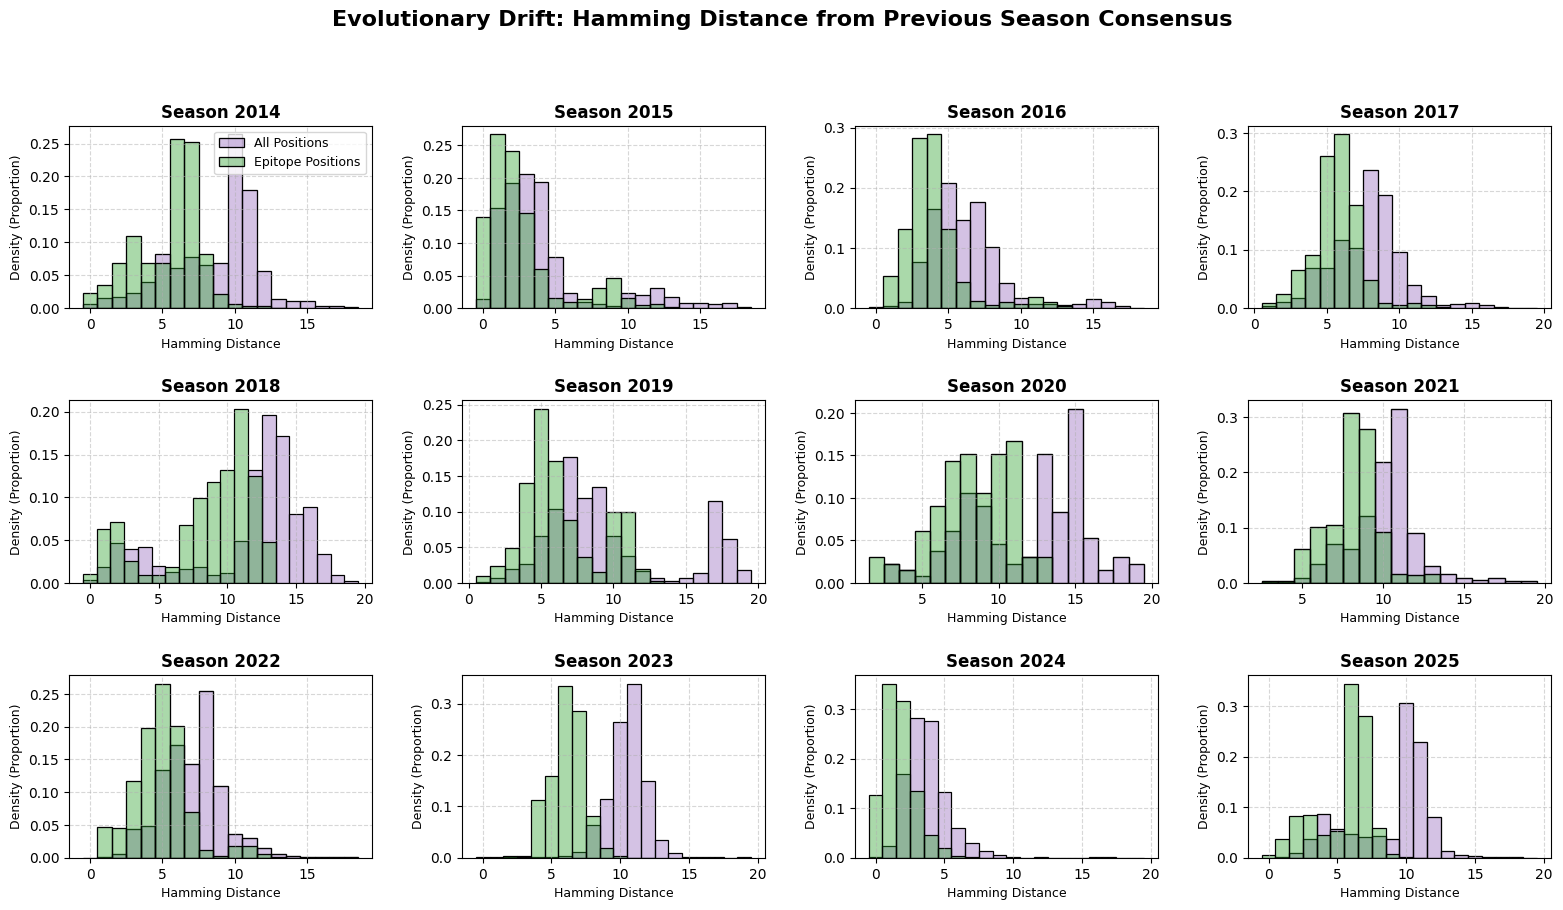

In [45]:
def plot_evolutionary_drift_histogram_unshared(df, col_all='Distance_All', col_epitope='Distance_Epitope'):
    print("Generating Independent Histogram plots for Evolutionary Drift...")
        
    if df.empty:
        print("No data available to plot.")
        return
        
    # Cap extreme outliers for cleaner visuals (top 1% of both columns)
    x_max_all = df[col_all].quantile(0.99) 
    x_max_epi = df[col_epitope].quantile(0.99)
    df_plot = df[(df[col_all] <= x_max_all) & (df[col_epitope] <= x_max_epi)].copy()

    # NOTE: Jitter is removed because histograms handle exact integer values perfectly.

    # Calculate grid dimensions
    seasons = sorted(df_plot['Season'].unique())
    num_seasons = len(seasons)
    
    cols = 4
    rows = math.ceil(num_seasons / cols)

    # Initialize a figure with independent axes
    fig, axes = plt.subplots(rows, cols, figsize=(16, 3 * rows), sharex=False, sharey=False)
    axes = axes.flatten()

    for i, season in enumerate(seasons):
        ax = axes[i]
        df_season = df_plot[df_plot['Season'] == season]
        
        # Plot histogram for ALL positions
        sns.histplot(
            data=df_season, x=col_all, color='tab:purple', label='All Positions',     
            stat='density', common_norm=False, alpha=0.4, ax=ax, discrete=True
        )
        
        # Plot histogram for EPITOPE positions
        sns.histplot(
            data=df_season, x=col_epitope, color='tab:green', label='Epitope Positions',     
            stat='density', common_norm=False, alpha=0.4, ax=ax, discrete=True
        )
        
        ax.set_title(f'Season {season}', fontsize=12, weight='bold')
        
        # Formatting for independent axes
        ax.set_xlabel('Hamming Distance', fontsize=9)
        ax.set_ylabel('Density (Proportion)', fontsize=9)
        ax.grid(True, linestyle='--', alpha=0.5)
        
        # Add legend only to the first plot
        if i == 0:
            ax.legend(loc='upper right', fontsize=9)

    # Clean up empty subplots
    for k in range(num_seasons, len(axes)):
        fig.delaxes(axes[k])

    # Main Title
    plt.suptitle('Evolutionary Drift: Hamming Distance from Previous Season Consensus', 
                 fontsize=16, weight='bold', y=1.02)
    
    plt.tight_layout(pad=2.0)
    plt.savefig("Evolutionary_Drift_Histogram_Unshared.png", dpi=300, bbox_inches='tight')
    plt.show()

# --- EXECUTE ---
plot_evolutionary_drift_histogram_unshared(df_distances)

Generating Histogram plots for Evolutionary Drift by Zone...


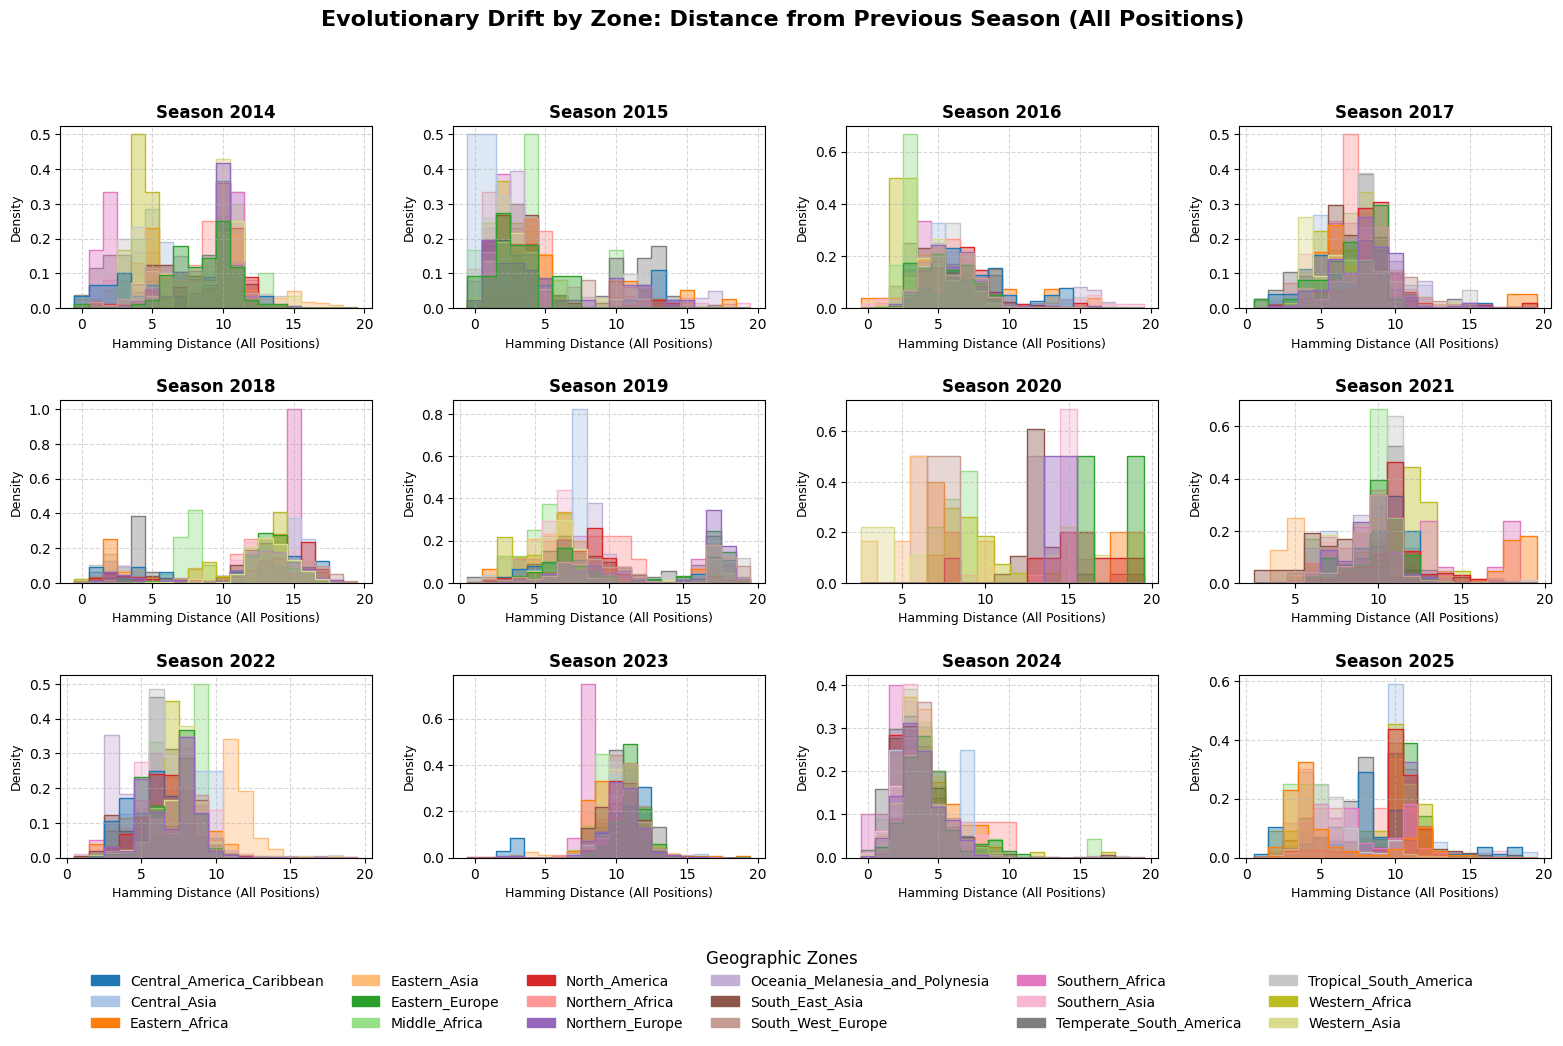

In [48]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import math
import numpy as np

def plot_drift_by_zone_histogram(df, col_dist='Distance_All'):
    print("Generating Histogram plots for Evolutionary Drift by Zone...")
        
    if df.empty:
        print("No data available to plot.")
        return
        
    # Cap extreme outliers for cleaner visuals
    x_max = df[col_dist].quantile(0.99) 
    df_plot = df[df[col_dist] <= x_max].copy()

    # Calculate grid dimensions
    seasons = sorted(df_plot['Season'].unique())
    num_seasons = len(seasons)
    cols = 4
    rows = math.ceil(num_seasons / cols)

    # --- COLOR PALETTE & LEGEND PREP ---
    # Get all unique zones to establish a consistent color mapping
    unique_zones = sorted(df_plot['Zone'].unique())
    num_zones = len(unique_zones)
    
    # 'tab20' is an excellent colormap for up to 20 distinct categorical colors
    palette = sns.color_palette("tab20", n_colors=num_zones)
    color_map = dict(zip(unique_zones, palette))

    # Initialize a figure
    fig, axes = plt.subplots(rows, cols, figsize=(16, 3 * rows), sharex=False, sharey=False)
    
    if num_seasons == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for i, season in enumerate(seasons):
        ax = axes[i]
        df_season = df_plot[df_plot['Season'] == season]
        
        # Plot histogram for ALL positions, colored by ZONE
        sns.histplot(
            data=df_season, 
            x=col_dist, 
            hue='Zone',
            palette=color_map,      # Use our assigned distinct colors
            multiple='layer',
            element='step',
            stat='density', 
            common_norm=False, 
            alpha=0.4, 
            ax=ax, 
            discrete=True,
            legend=False            # TURNING OFF default individual legends
        )
        
        ax.set_title(f'Season {season}', fontsize=12, weight='bold')
        ax.set_xlabel('Hamming Distance (All Positions)', fontsize=9)
        ax.set_ylabel('Density', fontsize=9)
        ax.grid(True, linestyle='--', alpha=0.5)

    # Clean up empty subplots
    for k in range(num_seasons, len(axes)):
        fig.delaxes(axes[k])

    plt.suptitle('Evolutionary Drift by Zone: Distance from Previous Season (All Positions)', 
                 fontsize=16, weight='bold', y=1.02)
    
    # --- MASTER LEGEND SETUP ---
    # Generate visual patches for the legend based on our exact color map
    legend_handles = [mpatches.Patch(color=color_map[zone], label=zone) for zone in unique_zones]
    
    # Calculate columns needed to ensure exactly 3 rows (e.g., 18 zones / 3 = 6 columns)
    legend_cols = math.ceil(num_zones / 3)
    
    # Place the legend globally at the bottom center of the figure
    fig.legend(
        handles=legend_handles, 
        loc='upper center', 
        bbox_to_anchor=(0.5, -0.01), # Pushes the legend strictly below the grid
        ncol=legend_cols, 
        title='Geographic Zones',
        title_fontsize='12',
        fontsize='10',
        frameon=False
    )

    plt.tight_layout(pad=2.0)
    # bbox_inches='tight' is crucial here so the external legend isn't cropped out when saving
    plt.savefig("Evolutionary_Drift_Zone_Histogram.png", dpi=300, bbox_inches='tight')
    plt.show()

# --- EXECUTE ---
plot_drift_by_zone_histogram(df_distances)

Generating Density plots for Evolutionary Drift by Zone...


/tmp/ipykernel_2645726/995531351.py:51: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


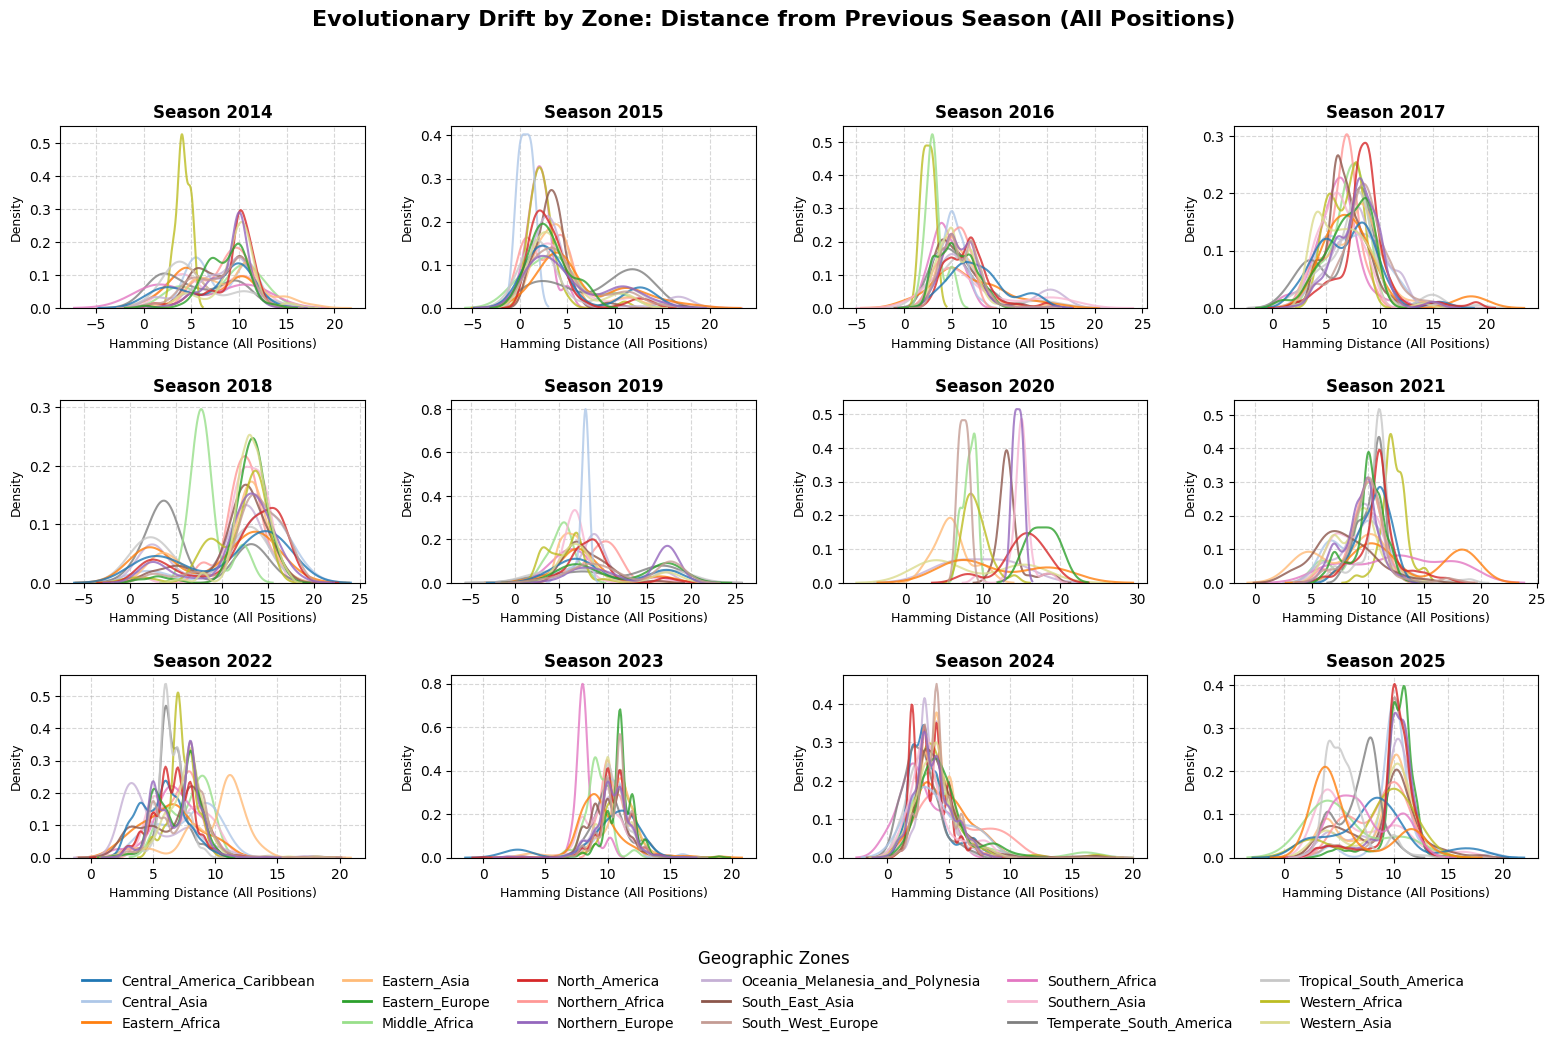

In [50]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import seaborn as sns
import math
import numpy as np

def plot_drift_by_zone_density(df, col_dist='Distance_All'):
    print("Generating Density plots for Evolutionary Drift by Zone...")
        
    if df.empty:
        print("No data available to plot.")
        return
        
    # Cap extreme outliers for cleaner visuals
    x_max = df[col_dist].quantile(0.99) 
    df_plot = df[df[col_dist] <= x_max].copy()

    # Add minor jitter (noise) to prevent errors on low-variance discrete distributions
    # (KDE requires continuous data to draw curves properly)
    df_plot[col_dist] = df_plot[col_dist] + np.random.normal(0, 0.1, size=len(df_plot))

    # Calculate grid dimensions
    seasons = sorted(df_plot['Season'].unique())
    num_seasons = len(seasons)
    cols = 4
    rows = math.ceil(num_seasons / cols)

    # --- COLOR PALETTE & LEGEND PREP ---
    unique_zones = sorted(df_plot['Zone'].unique())
    num_zones = len(unique_zones)
    
    # Use 'tab20' for highly distinct colors
    palette = sns.color_palette("tab20", n_colors=num_zones)
    color_map = dict(zip(unique_zones, palette))

    # Initialize a figure
    fig, axes = plt.subplots(rows, cols, figsize=(16, 3 * rows), sharex=False, sharey=False)
    
    if num_seasons == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for i, season in enumerate(seasons):
        ax = axes[i]
        df_season = df_plot[df_plot['Season'] == season]
        
        # Plot density (KDE) for ALL positions, colored by ZONE
        # Using a try/except block in case a zone has too few samples for a KDE curve
        try:
            sns.kdeplot(
                data=df_season, 
                x=col_dist, 
                hue='Zone',
                palette=color_map,
                common_norm=False, 
                fill=False,         # Use lines instead of fill so 18 zones don't turn into a solid blob
                linewidth=1.5,
                alpha=0.8, 
                ax=ax, 
                legend=False,       # Turn off default legend
                bw_adjust=0.8
            )
        except Exception as e:
            print(f"Skipping KDE for season {season}: {e}")
            
        ax.set_title(f'Season {season}', fontsize=12, weight='bold')
        ax.set_xlabel('Hamming Distance (All Positions)', fontsize=9)
        ax.set_ylabel('Density', fontsize=9)
        ax.grid(True, linestyle='--', alpha=0.5)

    # Clean up empty subplots
    for k in range(num_seasons, len(axes)):
        fig.delaxes(axes[k])

    plt.suptitle('Evolutionary Drift by Zone: Distance from Previous Season (All Positions)', 
                 fontsize=16, weight='bold', y=1.02)
    
    # --- MASTER LEGEND SETUP ---
    # Generate line handles for the legend matching the KDE plot lines
    legend_handles = [mlines.Line2D([], [], color=color_map[zone], linewidth=2, label=zone) for zone in unique_zones]
    
    # Calculate columns needed to ensure exactly 3 rows
    legend_cols = math.ceil(num_zones / 3)
    
    fig.legend(
        handles=legend_handles, 
        loc='upper center', 
        bbox_to_anchor=(0.5, -0.01), 
        ncol=legend_cols, 
        title='Geographic Zones',
        title_fontsize='12',
        fontsize='10',
        frameon=False
    )

    plt.tight_layout(pad=2.0)
    plt.savefig("Evolutionary_Drift_Zone_Density.png", dpi=300, bbox_inches='tight')
    plt.show()

# --- EXECUTE ---
plot_drift_by_zone_density(df_distances)

Generating Density plots for Evolutionary Drift by specific Zones...


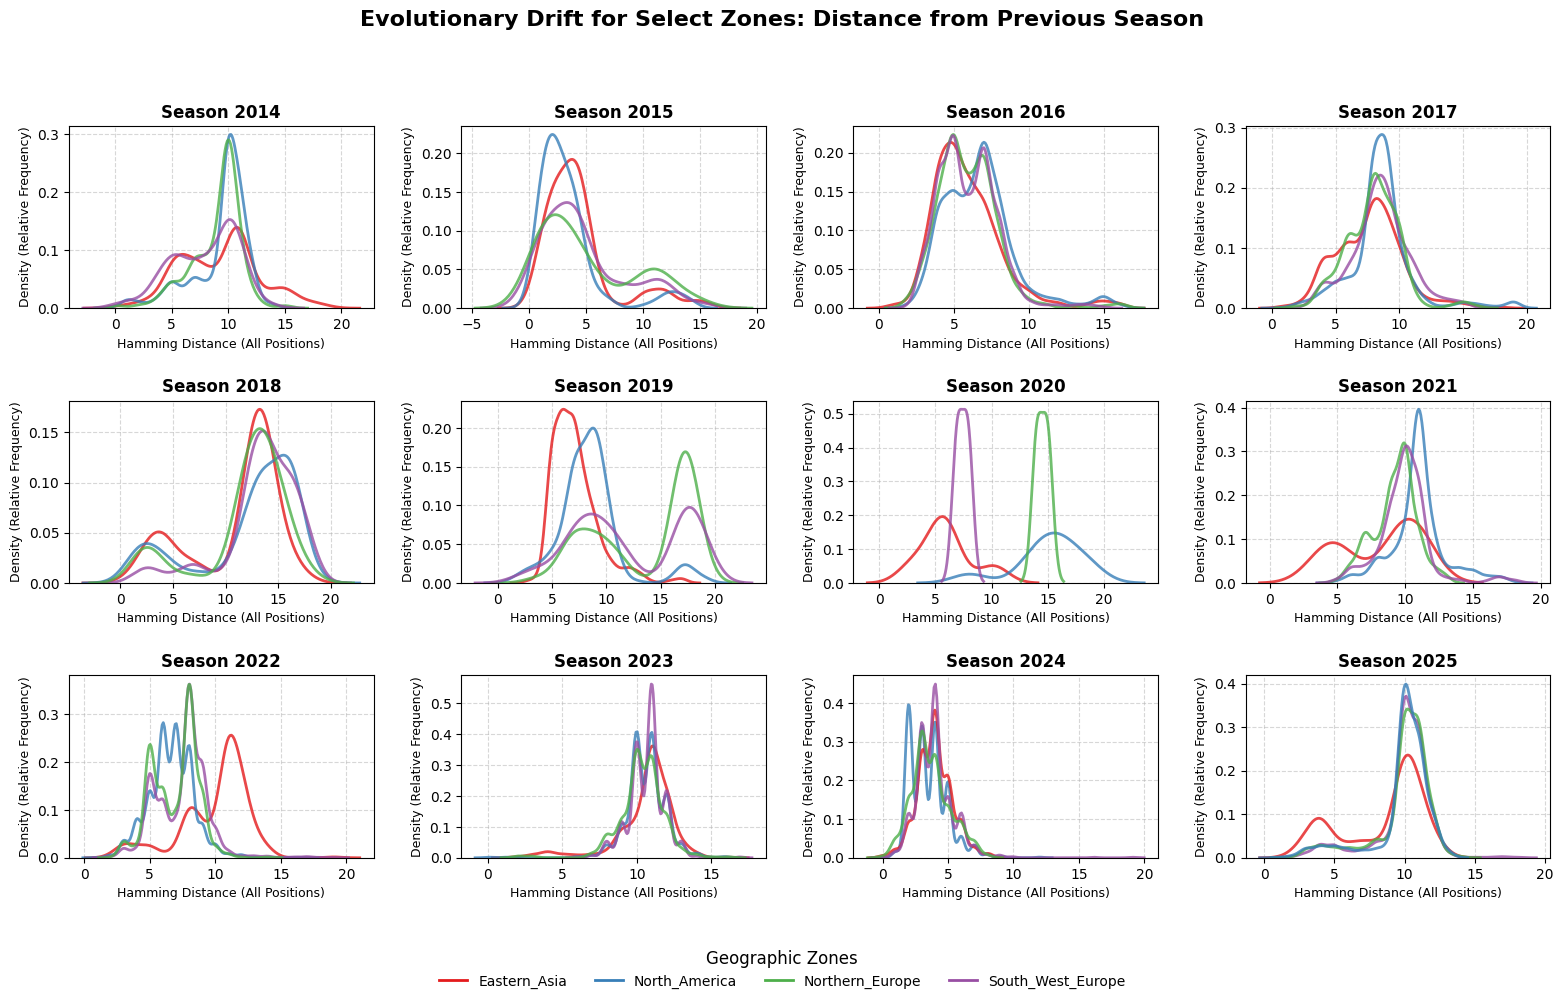

In [52]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import seaborn as sns
import math
import numpy as np

def plot_drift_by_zone_density(df, col_dist='Distance_All'):
    print("Generating Density plots for Evolutionary Drift by specific Zones...")
        
    if df.empty:
        print("No data available to plot.")
        return
        
    # --- NEW: Filter DataFrame to include only the specified zones ---
    target_zones = ['North_America', 'South_West_Europe', 'Northern_Europe', 'Eastern_Asia']
    df_filtered = df[df['Zone'].isin(target_zones)].copy()
    
    if df_filtered.empty:
        print("No data available for the specified zones.")
        return

    # Cap extreme outliers for cleaner visuals
    x_max = df_filtered[col_dist].quantile(0.99) 
    df_plot = df_filtered[df_filtered[col_dist] <= x_max].copy()

    # Add minor jitter (noise) to prevent errors on low-variance discrete distributions
    df_plot[col_dist] = df_plot[col_dist] + np.random.normal(0, 0.1, size=len(df_plot))

    # Calculate grid dimensions
    seasons = sorted(df_plot['Season'].unique())
    num_seasons = len(seasons)
    cols = 4
    rows = math.ceil(num_seasons / cols)

    # --- COLOR PALETTE & LEGEND PREP ---
    unique_zones = sorted(df_plot['Zone'].unique())
    num_zones = len(unique_zones)
    
    # Swapped to 'Set1' as it provides stronger, more distinct colors for a smaller number of categories
    palette = sns.color_palette("Set1", n_colors=num_zones)
    color_map = dict(zip(unique_zones, palette))

    # Initialize a figure
    fig, axes = plt.subplots(rows, cols, figsize=(16, 3 * rows), sharex=False, sharey=False)
    
    if num_seasons == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for i, season in enumerate(seasons):
        ax = axes[i]
        df_season = df_plot[df_plot['Season'] == season]
        
        try:
            sns.kdeplot(
                data=df_season, 
                x=col_dist, 
                hue='Zone',
                palette=color_map,
                common_norm=False, 
                fill=False,         
                linewidth=2.0,      # Slightly thicker lines since there are fewer zones overlapping
                alpha=0.8, 
                ax=ax, 
                legend=False,       
                bw_adjust=0.8
            )
        except Exception as e:
            print(f"Skipping KDE for season {season}: {e}")
            
        ax.set_title(f'Season {season}', fontsize=12, weight='bold')
        ax.set_xlabel('Hamming Distance (All Positions)', fontsize=9)
        ax.set_ylabel('Density (Relative Frequency)', fontsize=9)
        ax.grid(True, linestyle='--', alpha=0.5)

    # Clean up empty subplots
    for k in range(num_seasons, len(axes)):
        fig.delaxes(axes[k])

    plt.suptitle('Evolutionary Drift for Select Zones: Distance from Previous Season', 
                 fontsize=16, weight='bold', y=1.02)
    
    # --- MASTER LEGEND SETUP ---
    legend_handles = [mlines.Line2D([], [], color=color_map[zone], linewidth=2, label=zone) for zone in unique_zones]
    
    # Set to 4 columns so the 4 zones lay out cleanly in a single row
    fig.legend(
        handles=legend_handles, 
        loc='upper center', 
        bbox_to_anchor=(0.5, -0.01), 
        ncol=4, 
        title='Geographic Zones',
        title_fontsize='12',
        fontsize='10',
        frameon=False
    )

    plt.tight_layout(pad=2.0)
    plt.savefig("Evolutionary_Drift_Specific_Zones_Density.png", dpi=300, bbox_inches='tight')
    plt.show()

# --- EXECUTE ---
plot_drift_by_zone_density(df_distances)

Generating Independent Density plots for Evolutionary Drift...


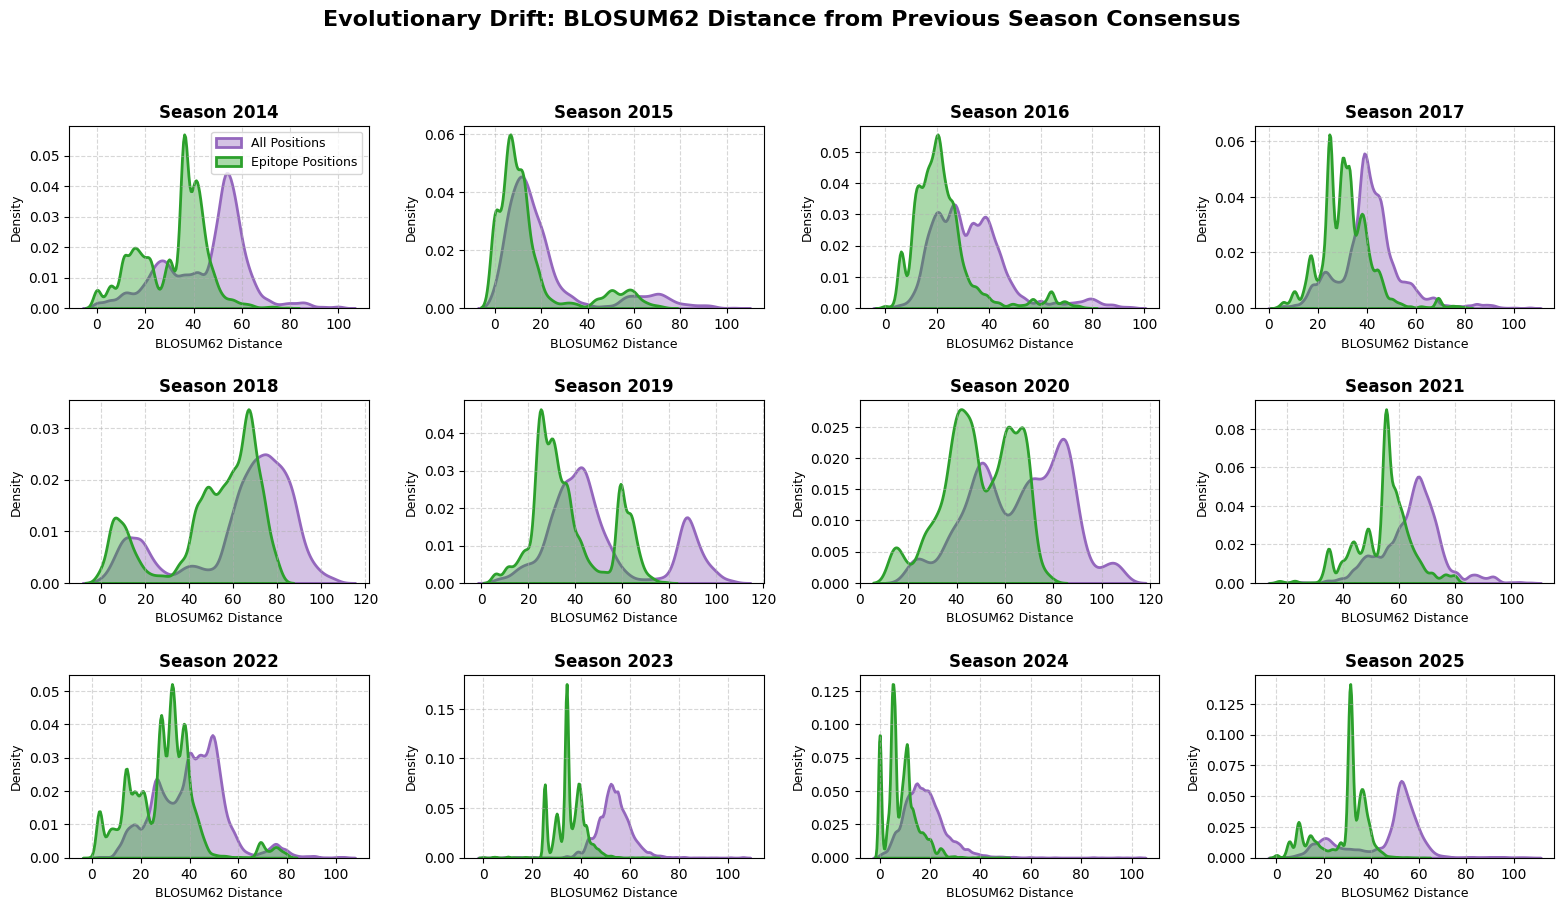

In [20]:
def plot_evolutionary_drift_density_unshared(df, col_all='Distance_All', col_epitope='Distance_Epitope'):
    print("Generating Independent Density plots for Evolutionary Drift...")
        
    if df.empty:
        print("No data available to plot.")
        return
        
    # Cap extreme outliers for cleaner visuals (top 1% of both columns)
    x_max_all = df[col_all].quantile(0.99) 
    x_max_epi = df[col_epitope].quantile(0.99)
    df_plot = df[(df[col_all] <= x_max_all) & (df[col_epitope] <= x_max_epi)].copy()

    # Add minor jitter to prevent flat lines on low-variance distributions
    df_plot[col_all] += np.random.normal(0, 0.05, size=len(df_plot))
    df_plot[col_epitope] += np.random.normal(0, 0.05, size=len(df_plot))

    # Calculate grid dimensions
    seasons = sorted(df_plot['Season'].unique())
    num_seasons = len(seasons)
    
    cols = 4
    rows = math.ceil(num_seasons / cols)

    # Initialize a figure with independent axes (sharex=False, sharey=False)
    fig, axes = plt.subplots(rows, cols, figsize=(16, 3 * rows), sharex=False, sharey=False)
    axes = axes.flatten()

    for i, season in enumerate(seasons):
        ax = axes[i]
        df_season = df_plot[df_plot['Season'] == season]
        
        # Plot density for ALL positions
        sns.kdeplot(
            data=df_season, x=col_all, color='tab:purple', label='All Positions',     
            common_norm=False, fill=True, linewidth=2, alpha=0.4, ax=ax,
            bw_adjust=0.5 # Lowered to reveal smaller bumps
        )
        
        # Plot density for EPITOPE positions
        sns.kdeplot(
            data=df_season, x=col_epitope, color='tab:green', label='Epitope Positions',     
            common_norm=False, fill=True, linewidth=2, alpha=0.4, ax=ax,
            bw_adjust=0.5 # Lowered to reveal smaller bumps
        )
        
        ax.set_title(f'Season {season}', fontsize=12, weight='bold')
        
        # Formatting for independent axes
        ax.set_xlabel('BLOSUM62 Distance', fontsize=9)
        ax.set_ylabel('Density', fontsize=9)
        ax.grid(True, linestyle='--', alpha=0.5)
        
        # Add legend only to the first plot
        if i == 0:
            ax.legend(loc='upper right', fontsize=9)

    # Clean up empty subplots
    for k in range(num_seasons, len(axes)):
        fig.delaxes(axes[k])

    # Main Title
    plt.suptitle('Evolutionary Drift: BLOSUM62 Distance from Previous Season Consensus', 
                 fontsize=16, weight='bold', y=1.02)
    
    # Increase spacing so independent axis labels don't overlap
    plt.tight_layout(pad=2.0)
    plt.savefig("Evolutionary_Drift_Density_Unshared.png", dpi=300, bbox_inches='tight')
    plt.show()

# --- EXECUTE ---
plot_evolutionary_drift_density_unshared(df_distances)

In [46]:
df_distances.head()

,Season,Zone,Distance_All,Distance_Epitope
0,2014,Eastern_Europe,10,7
1,2014,Eastern_Europe,6,3
2,2014,Eastern_Europe,13,6
3,2014,Eastern_Europe,10,7
4,2014,Eastern_Europe,10,6


Generating Small Multiples Density plot for Evolutionary Drift...


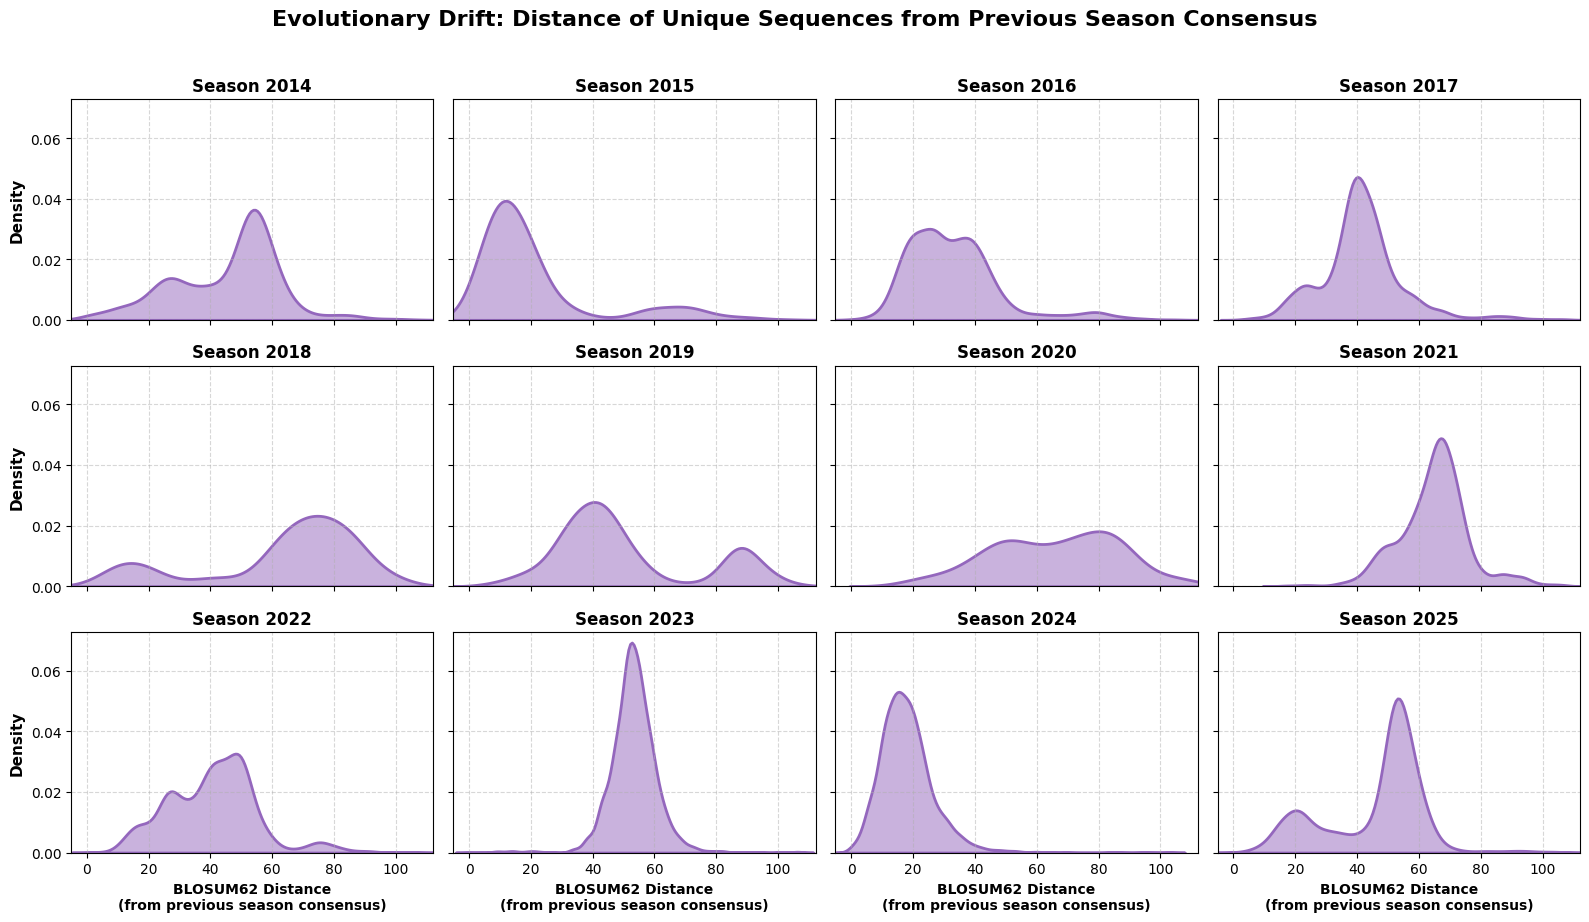

In [4]:

def plot_evolutionary_drift_density(df, metric_col='Distance'):
    print(f"Generating Small Multiples Density plot for Evolutionary Drift...")
        
    if df.empty:
        print("No data available to plot.")
        return
        
    # Cap extreme outliers for cleaner visuals (top 1%)
    x_max = df[metric_col].quantile(0.99) 
    df_plot = df[df[metric_col] <= x_max].copy()

    # Add minor jitter to prevent flat lines on low-variance distributions
    df_plot[metric_col] = df_plot[metric_col] + np.random.normal(0, 0.05, size=len(df_plot))

    # Calculate grid dimensions
    seasons = sorted(df_plot['Season'].unique())
    num_seasons = len(seasons)
    
    cols = 4
    rows = math.ceil(num_seasons / cols)

    # Initialize a figure with rows x 4 columns
    fig, axes = plt.subplots(rows, cols, figsize=(16, 3 * rows), sharex=True, sharey=True)
    axes = axes.flatten()
    
    # Determine global X-axis limits for consistent comparison
    global_x_min = df_plot[metric_col].min() - 5
    global_x_max = df_plot[metric_col].max() + 5

    for i, season in enumerate(seasons):
        ax = axes[i]
        df_season = df_plot[df_plot['Season'] == season]
        
        # Plot density
        sns.kdeplot(
            data=df_season, x=metric_col, color='tab:purple',     
            common_norm=False, fill=True, linewidth=2, alpha=0.5, ax=ax
        )
        
        ax.set_title(f'Season {season}', fontsize=12, weight='bold')
        ax.set_xlim(global_x_min, global_x_max)
        
        # Formatting
        ax.set_xlabel('BLOSUM62 Distance\n(from previous season consensus)' if i >= len(axes) - cols else '', fontsize=10, weight='bold')
        ax.set_ylabel('Density' if i % cols == 0 else '', fontsize=11, weight='bold')
        
        ax.grid(True, linestyle='--', alpha=0.5)

    # Clean up empty subplots
    for k in range(num_seasons, len(axes)):
        fig.delaxes(axes[k])

    # Main Title
    plt.suptitle('Evolutionary Drift: Distance of Unique Sequences from Previous Season Consensus', 
                 fontsize=16, weight='bold', y=1.02)
    
    plt.tight_layout()
    plt.savefig("Evolutionary_Drift_Density.png", dpi=300, bbox_inches='tight')
    plt.show()

# --- EXECUTE ---
plot_evolutionary_drift_density(df_distances)

In [5]:
from itertools import chain

epitope_sites = {
    'A': [122, 124, 126, 130, 131, 132, 133, 135, 137, 138, 140, 142, 143, 144, 145, 146, 150, 152, 168],
    'B': [128, 129, 155, 156, 157, 158, 159, 160, 163, 164, 165, 186, 187, 188, 189, 190, 192, 193, 194, 196, 197, 198],
    'C': [44, 45, 46, 47, 48, 50, 51, 53, 54, 273, 275, 276, 278, 279, 280, 294, 297, 299, 300, 304, 305, 307, 308, 309, 310, 311, 312],
    'D': [96, 102, 103, 117, 121, 167, 170, 171, 172, 173, 174, 175, 176, 177, 179, 182, 201, 203, 207, 208, 209, 212, 213, 214, 215, 216, 217, 218, 219, 226, 227, 228, 229, 230, 238, 240, 242, 244, 246, 247, 248],
    'E': [57, 59, 62, 63, 67, 75, 78, 80, 81, 82, 83, 86, 87, 88, 91, 92, 94, 109, 260, 261, 262, 265]
}

ALL_EPITOPE_POSITIONS_1BASED = sorted(set(chain.from_iterable(epitope_sites.values())))
EPITOPE_INDICES_0BASED = [p - 1 for p in ALL_EPITOPE_POSITIONS_1BASED]

print(f"Total epitope positions: {len(EPITOPE_INDICES_0BASED)}")

Total epitope positions: 131


In [6]:
def get_epitope_seq(seq, indices):
    """Safely extracts only the characters at the specified indices."""
    return "".join([seq[i] for i in indices if i < len(seq)])

distance_records_epitope = []
target_seasons = range(2014, 2026)

print("Calculating Distances for Epitope Regions Only...")
for target_year in target_seasons:
    prev_year = target_year - 1
    
    # 1. Get previous season sequences and calculate global consensus
    df_prev = df_fasta[df_fasta['Season'] == prev_year]
    if df_prev.empty:
        print(f"  [!] No data for previous season {prev_year}. Skipping target {target_year}.")
        continue
        
    prev_consensus = get_consensus(df_prev['sequence'].tolist())
    # Extract only the epitope positions from the consensus
    prev_consensus_epi = get_epitope_seq(prev_consensus, EPITOPE_INDICES_0BASED)
    
    # 2. Get target season data
    df_target = df_fasta[df_fasta['Season'] == target_year]
    if df_target.empty:
        continue
        
    # 3. Get unique sequences per zone
    df_unique_target = df_target.drop_duplicates(subset=['zone', 'sequence'])
    
    # 4. Calculate distances using ONLY epitope positions
    for _, row in df_unique_target.iterrows():
        target_seq_epi = get_epitope_seq(row['sequence'], EPITOPE_INDICES_0BASED)
        dist = calc_blosum_distance(prev_consensus_epi, target_seq_epi)
        
        distance_records_epitope.append({
            'Season': target_year,
            'Zone': row['zone'],
            'Epitope_Distance': dist
        })

df_epitope_distances = pd.DataFrame(distance_records_epitope)
print(f"Calculated epitope distances for {len(df_epitope_distances)} unique sequence-zone pairs.")

Calculating Distances for Epitope Regions Only...
Calculated epitope distances for 33189 unique sequence-zone pairs.


Generating Small Multiples Density plot for Epitope Drift...


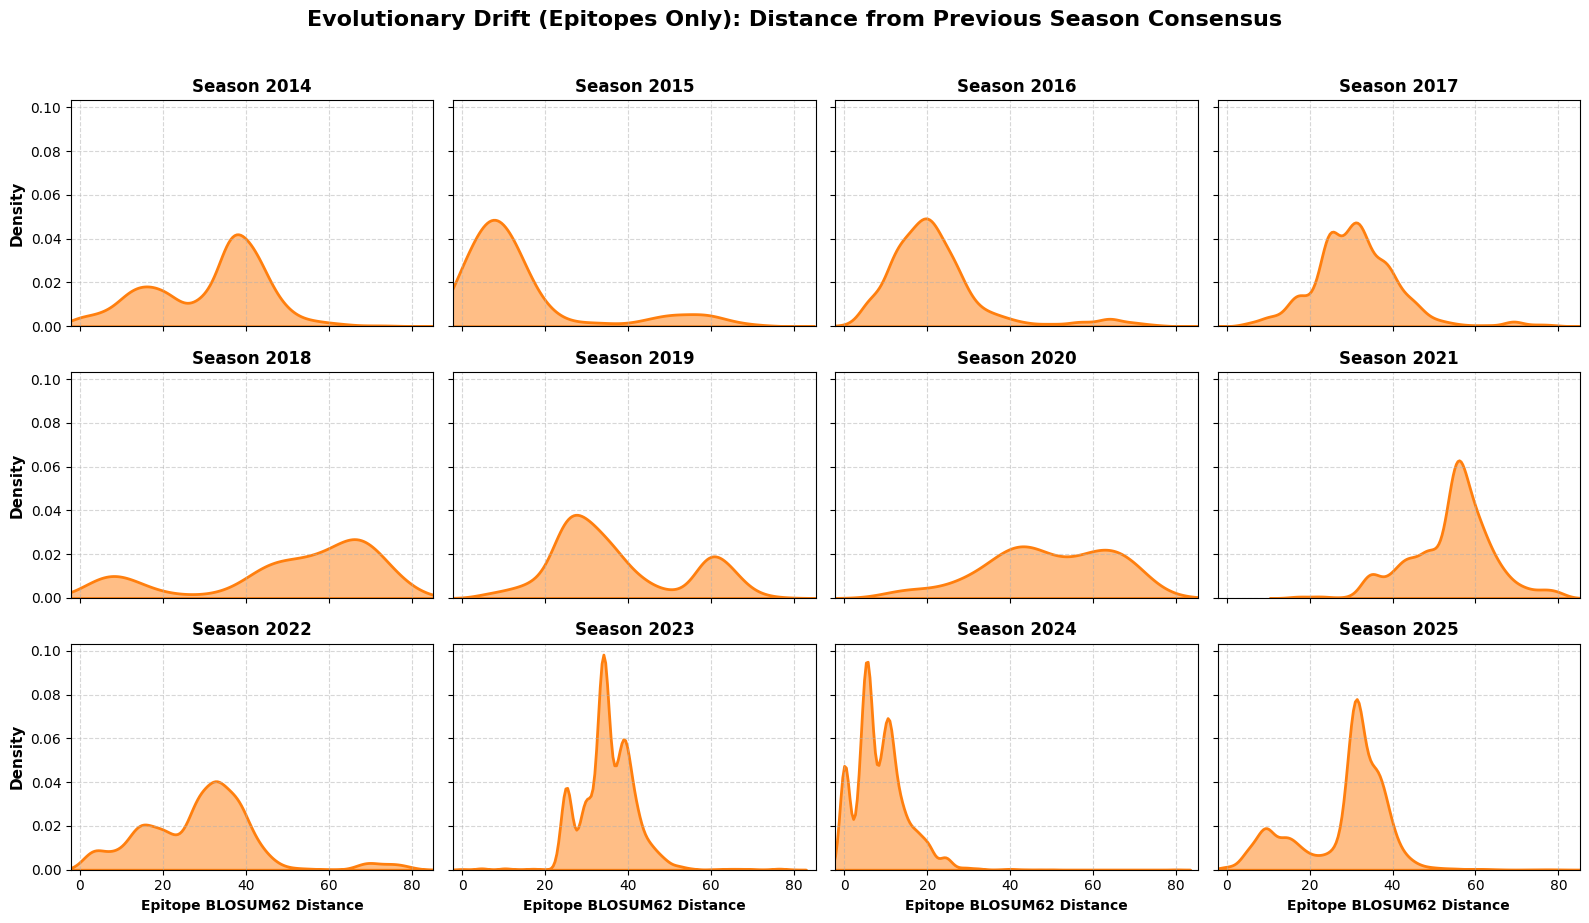

In [11]:
def plot_epitope_drift_density(df, metric_col='Epitope_Distance'):
    print(f"Generating Small Multiples Density plot for Epitope Drift...")
        
    if df.empty:
        print("No data available to plot.")
        return
        
    # Cap extreme outliers for cleaner visuals (top 1%)
    x_max = df[metric_col].quantile(0.99) 
    df_plot = df[df[metric_col] <= x_max].copy()

    # Add minor jitter to prevent flat lines on low-variance distributions
    df_plot[metric_col] = df_plot[metric_col] + np.random.normal(0, 0.05, size=len(df_plot))

    # Calculate grid dimensions
    seasons = sorted(df_plot['Season'].unique())
    num_seasons = len(seasons)
    
    cols = 4
    rows = math.ceil(num_seasons / cols)

    # Initialize a figure with rows x 4 columns
    fig, axes = plt.subplots(rows, cols, figsize=(16, 3 * rows), sharex=True, sharey=True)
    axes = axes.flatten()
    
    # Determine global X-axis limits for consistent comparison
    global_x_min = df_plot[metric_col].min() - 2
    global_x_max = df_plot[metric_col].max() + 5

    for i, season in enumerate(seasons):
        ax = axes[i]
        df_season = df_plot[df_plot['Season'] == season]
        
        # Plot density (using an orange/coral color to distinguish from the all-positions graph)
        sns.kdeplot(
            data=df_season, x=metric_col, color='tab:orange',     
            common_norm=False, fill=True, linewidth=2, alpha=0.5, ax=ax
        )
        
        ax.set_title(f'Season {season}', fontsize=12, weight='bold')
        ax.set_xlim(global_x_min, global_x_max)
        
        # Formatting
        ax.set_xlabel('Epitope BLOSUM62 Distance' if i >= len(axes) - cols else '', fontsize=10, weight='bold')
        ax.set_ylabel('Density' if i % cols == 0 else '', fontsize=11, weight='bold')
        
        ax.grid(True, linestyle='--', alpha=0.5)

    # Clean up empty subplots
    for k in range(num_seasons, len(axes)):
        fig.delaxes(axes[k])

    # Main Title
    plt.suptitle('Evolutionary Drift (Epitopes Only): Distance from Previous Season Consensus', 
                 fontsize=16, weight='bold', y=1.02)
    
    plt.tight_layout()
    plt.savefig("Evolutionary_Drift_Epitope_Density.png", dpi=300, bbox_inches='tight')
    plt.show()

# --- EXECUTE ---
plot_epitope_drift_density(df_epitope_distances)

In [32]:
def calc_match_percentage(seq1, seq2, positions=None):
    """
    Calculates the % identity between two aligned sequences.
    If positions are provided, it only checks those specific indices.
    """
    # Truncate to the shorter sequence to avoid index errors, assuming aligned
    min_len = min(len(seq1), len(seq2))
    
    if positions is None:
        positions = range(min_len)
    else:
        # Filter out positions that exceed sequence length
        positions = [p for p in positions if p < min_len]
        
    if not positions:
        return 0.0
        
    matches = sum(1 for i in positions if seq1[i] == seq2[i])
    return (matches / len(positions)) * 100

# --- SETUP VARIABLES ---
# Define your epitope positions (0-indexed integers). 
# Example: [140, 141, 142, 145, ...]
epitope_indices = [10, 25, 50, 140, 142] # REPLACE THIS with your actual epitope list

accuracy_records = []
target_seasons = range(2014, 2026) # 2014 to 2025

print("Calculating Accuracies...")
for target_year in target_seasons:
    prev_year = target_year - 1
    
    # 1. Get previous season sequences and calculate global consensus
    df_prev = df_fasta[df_fasta['Season'] == prev_year]
    if df_prev.empty:
        print(f"  [!] No data for previous season {prev_year}. Skipping target {target_year}.")
        continue
        
    prev_consensus = get_consensus(df_prev['sequence'].tolist())
    
    # 2. Get target season data
    df_target = df_fasta[df_fasta['Season'] == target_year]
    if df_target.empty:
        continue
        
    # 3. Get unique sequences per zone for the target season
    df_unique_target = df_target.drop_duplicates(subset=['zone', 'sequence'])
    
    # 4. Calculate accuracy percentages
    for _, row in df_unique_target.iterrows():
        seq = row['sequence']
        
        # Calculate for all positions
        acc_all = calc_match_percentage(prev_consensus, seq)
        # Calculate for only epitope positions
        acc_epitope = calc_match_percentage(prev_consensus, seq, positions=EPITOPE_INDICES_0BASED)

        accuracy_records.append({
            'Season': target_year,
            'Zone': row['zone'],
            'Accuracy_All': acc_all,
            'Accuracy_Epitope': acc_epitope
        })

df_accuracies = pd.DataFrame(accuracy_records)
print(f"Calculated accuracies for {len(df_accuracies)} unique sequence-zone pairs.")

Calculating Accuracies...
Calculated accuracies for 33189 unique sequence-zone pairs.


In [31]:
df_distances.groupby('Distance_Epitope')['Distance_Epitope'].count()

Distance_Epitope
0.0      881
1.0       67
2.0       15
3.0      392
4.0      253
        ... 
681.0      1
690.0      1
748.0      2
758.0      2
888.0      1
Name: Distance_Epitope, Length: 208, dtype: int64

In [33]:
df_accuracies.groupby('Accuracy_Epitope')['Accuracy_Epitope'].count()

Accuracy_Epitope
0.000000         4
7.633588         1
9.160305         1
9.923664         2
12.213740        1
              ... 
96.946565     3464
97.709924     3162
98.473282     3223
99.236641     2844
100.000000     881
Name: Accuracy_Epitope, Length: 67, dtype: int64

Generating Independent Density plots for Sequence Accuracy...


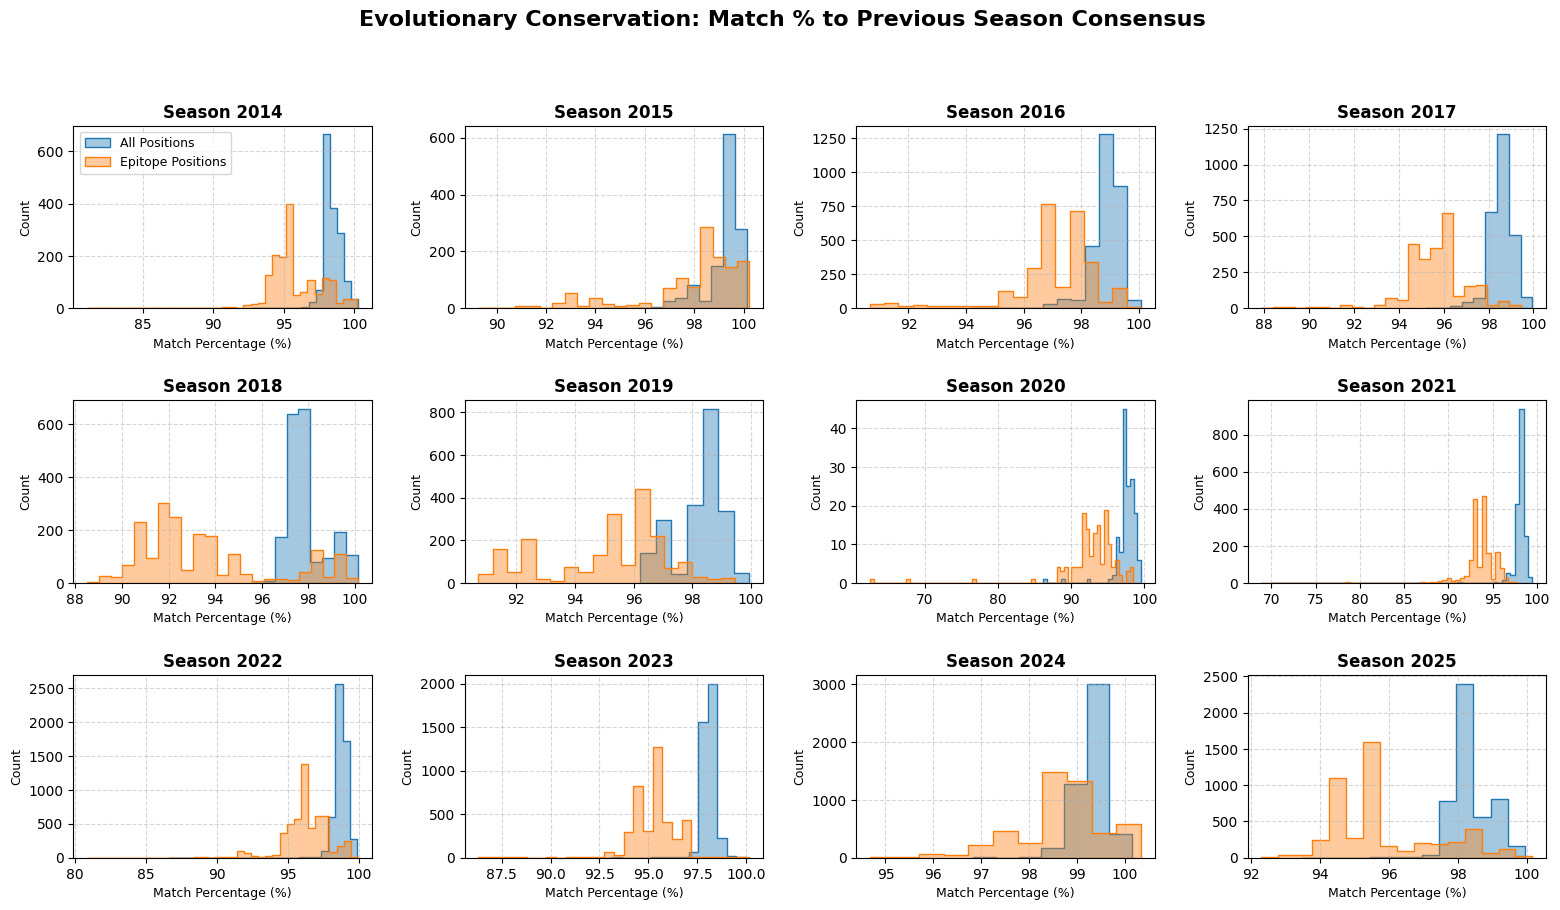

In [37]:
def plot_accuracy_density_unshared(df, lower_quantile=0.005):
    """
    lower_quantile=0.005 removes the bottom 0.5% of extreme outliers 
    per season so the X-axis can zoom in automatically.
    """
    print("Generating Independent Density plots for Sequence Accuracy...")
        
    if df.empty:
        print("No data available to plot.")
        return
        
    df_plot = df.copy()

    # Add minor jitter to prevent flat lines on low-variance distributions 
    df_plot['Accuracy_All'] += np.random.normal(0, 0.1, size=len(df_plot))
    df_plot['Accuracy_Epitope'] += np.random.normal(0, 0.1, size=len(df_plot))

    # Calculate grid dimensions
    seasons = sorted(df_plot['Season'].unique())
    num_seasons = len(seasons)
    
    cols = 4
    rows = math.ceil(num_seasons / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(16, 3 * rows), sharex=False, sharey=False)
    axes = axes.flatten()

    for i, season in enumerate(seasons):
        ax = axes[i]
        df_season = df_plot[df_plot['Season'] == season]
        
        # --- DYNAMIC OUTLIER REMOVAL ---
        # Find the threshold for the bottom X% of the data for this specific season
        q_all = df_season['Accuracy_All'].quantile(lower_quantile)
        q_epi = df_season['Accuracy_Epitope'].quantile(lower_quantile)
        
        # Take the minimum of the two thresholds to ensure we don't over-crop
        min_threshold = min(q_all, q_epi)
        
        # Filter out the extreme bottom outliers
        df_season_filtered = df_season[
            (df_season['Accuracy_All'] >= min_threshold) & 
            (df_season['Accuracy_Epitope'] >= min_threshold)
        ]
        # -------------------------------
        
        sns.histplot(
            data=df_season_filtered, x='Accuracy_All', color='tab:blue', label='All Positions',    
            element='step', fill=True, alpha=0.4, ax=ax,
            binwidth=0.5 
        )
        
        sns.histplot(
            data=df_season_filtered, x='Accuracy_Epitope', color='tab:orange', label='Epitope Positions',    
            element='step', fill=True, alpha=0.4, ax=ax,
            binwidth=0.5 
        )
        
        ax.set_title(f'Season {season}', fontsize=12, weight='bold')
        
        # Formatting
        ax.set_xlabel('Match Percentage (%)', fontsize=9)
        ax.set_ylabel('Count', fontsize=9) # Changed from Density since we are using counts
        ax.grid(True, linestyle='--', alpha=0.5)

        # Add legend only to the first plot
        if i == 0:
            ax.legend(loc='upper left', fontsize=9)

    # Clean up empty subplots
    for k in range(num_seasons, len(axes)):
        fig.delaxes(axes[k])

    # Main Title
    plt.suptitle('Evolutionary Conservation: Match % to Previous Season Consensus', 
                 fontsize=16, weight='bold', y=1.02)
    
    plt.tight_layout(pad=2.0)
    plt.savefig("Accuracy_with_train_consensus.png", dpi=300, bbox_inches='tight')
    plt.show()

# --- EXECUTE ---
plot_accuracy_density_unshared(df_accuracies, lower_quantile=0.005)

Generating Density plots for Sequence Accuracy with fixed X-limits...


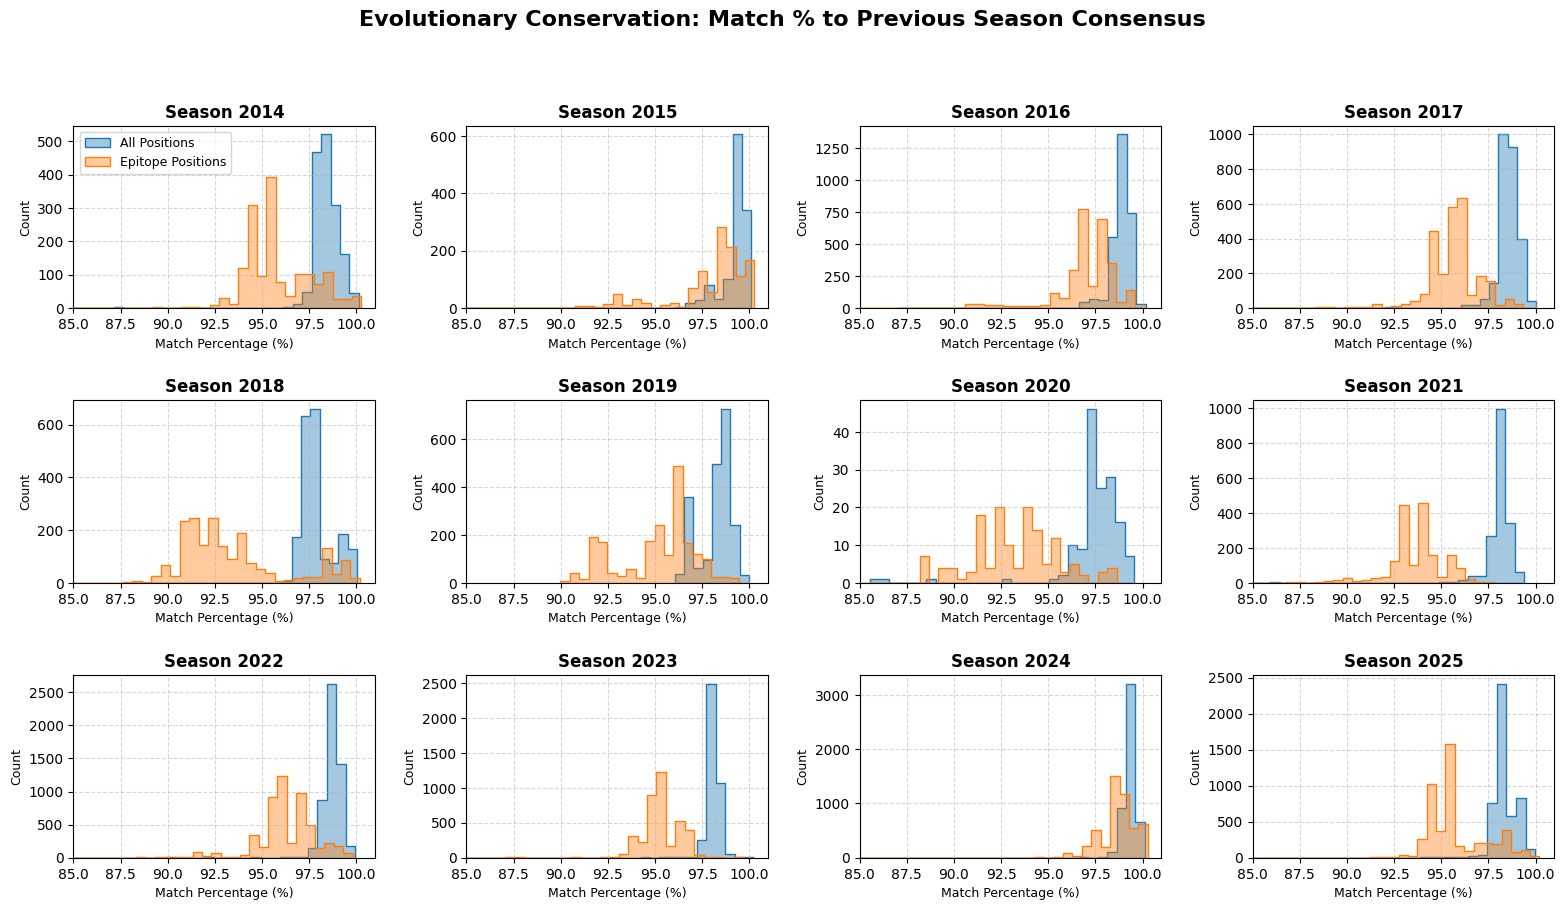

In [39]:
def plot_accuracy_density_fixed_xlim(df, x_limits=(80, 101)):
    """
    Plots histograms with a fixed X-axis limit for all seasons 
    to easily compare shifts across years.
    """
    print("Generating Density plots for Sequence Accuracy with fixed X-limits...")
        
    if df.empty:
        print("No data available to plot.")
        return
        
    df_plot = df.copy()

    # Add minor jitter to prevent flat lines on low-variance distributions 
    df_plot['Accuracy_All'] += np.random.normal(0, 0.1, size=len(df_plot))
    df_plot['Accuracy_Epitope'] += np.random.normal(0, 0.1, size=len(df_plot))

    # Calculate grid dimensions
    seasons = sorted(df_plot['Season'].unique())
    num_seasons = len(seasons)
    
    cols = 4
    rows = math.ceil(num_seasons / cols)

    # sharey=False allows each season's count to scale naturally
    fig, axes = plt.subplots(rows, cols, figsize=(16, 3 * rows), sharex=False, sharey=False)
    axes = axes.flatten()

    for i, season in enumerate(seasons):
        ax = axes[i]
        df_season = df_plot[df_plot['Season'] == season]
        
        # Plot All Positions
        sns.histplot(
            data=df_season, x='Accuracy_All', color='tab:blue', label='All Positions',    
            element='step', fill=True, alpha=0.4, ax=ax,
            binwidth=0.5 
        )
        
        # Plot Epitope Positions
        sns.histplot(
            data=df_season, x='Accuracy_Epitope', color='tab:orange', label='Epitope Positions',    
            element='step', fill=True, alpha=0.4, ax=ax,
            binwidth=0.5 
        )
        
        ax.set_title(f'Season {season}', fontsize=12, weight='bold')
        
        # --- FIXED X-AXIS ---
        ax.set_xlim(x_limits)
        # --------------------
        
        # Formatting
        ax.set_xlabel('Match Percentage (%)', fontsize=9)
        ax.set_ylabel('Count', fontsize=9) 
        ax.grid(True, linestyle='--', alpha=0.5)

        # Add legend only to the first plot
        if i == 0:
            ax.legend(loc='upper left', fontsize=9)

    # Clean up empty subplots
    for k in range(num_seasons, len(axes)):
        fig.delaxes(axes[k])

    # Main Title
    plt.suptitle('Evolutionary Conservation: Match % to Previous Season Consensus', 
                 fontsize=16, weight='bold', y=1.02)
    
    plt.tight_layout(pad=2.0)
    plt.savefig("Accuracy_with_prev_consensus.png", dpi=300, bbox_inches='tight')
    plt.show()

# --- EXECUTE ---
# You can change (80, 101) to whatever window best captures your data, e.g., (85, 101) or (70, 100)
plot_accuracy_density_fixed_xlim(df_accuracies, x_limits=(85, 101))